<a href="https://colab.research.google.com/github/raneem-a1/IT326-Heart-Disease-project/blob/main/final_report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IT326 - Data Mining Project
# Final Report

---

## 1. Problem




##2. Data Mining Task


##3. Data

##4. Data Preprocessing

###**4.3 Preprocessing Technique 3: Discretization**

Discretization converts continuous numerical values into a small number of categories (ranges). It simplifies the data and makes it easier to interpret.

**-Why?**

Age is a continuous attribute with many different values. Grouping it into age ranges makes it easier to interpret and to compare patients by life stage instead of by exact age.

**-Which attribute?**

The `age` attribute was selected because it is a continuous numerical attribute.

**-How?**

Discretization was applied after normalization, so the `age` values were already scaled between 0 and 1. These values were divided into three ranges using `pd.cut()`, creating a new categorical attribute called `age_group` (the original `age` column was kept):

| Category | Normalized age range | Approximate real age |
|---|---|---|
| Young | 0 – 0.4 | 29 – 48 years |
| Middle-aged | 0.4 – 0.7 | 49 – 62 years |
| Older | 0.7 – 1.0 | 63 – 77 years |

In [ ]:
# Apply Discretization on age

df_final = df_normalized.copy()

df_final['age_group'] = pd.cut(
    df_final['age'],
    bins=[0, 0.4, 0.7, 1],
    labels=['Young', 'Middle-aged', 'Older'],
    include_lowest=True
)

df_final.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,age_group
0,0.479167,1,0,0.292453,0.196347,0,1,0.740458,0,0.351124,2,2,3,0,Middle-aged
1,0.500000,1,0,0.433962,0.175799,1,0,0.641221,1,0.714756,0,0,3,0,Middle-aged
2,0.854167,1,0,0.481132,0.109589,0,1,0.412214,1,0.648876,0,0,3,0,Older
3,0.666667,1,0,0.509434,0.175799,0,1,0.687023,0,0.000000,2,1,3,0,Middle-aged
4,0.687500,0,0,0.415094,0.383562,1,1,0.267176,0,0.539345,1,3,2,0,Middle-aged


In [ ]:
# Check the distribution of age groups
df_final['age_group'].value_counts(dropna=False)

,count
age_group,
Middle-aged,544
Young,277
Older,204


**-Result:**

A new categorical attribute `age_group` was created with three categories. Middle-aged is the largest group (544 records, 53%), followed by Young (277 records, 27%) and Older (204 records, 20%). Every record was assigned to a category.

**-How did it improve the dataset?**

Discretization simplified the continuous age values into three meaningful age groups, making the attribute easier to interpret and analyze.

*Note:* `age_group` is used for interpretation only. In Section 6 it is removed from the inputs of the Decision Tree and K-Means models, because it is a text column derived from `age`, which is already included.

###**4.4 Final Preprocessed Dataset**

After applying the three preprocessing techniques, the final dataset is saved separately as `Preprocessed_dataset.csv`, while the original dataset is kept unchanged as `Raw_dataset.csv`.

In [ ]:
# Save Preprocessed dataset

df_final.to_csv("Preprocessed_dataset.csv", index=False)

print("Preprocessed dataset saved successfully!")

Preprocessed dataset saved successfully!


**Raw vs Preprocessed Dataset**

The snapshot below compares the first rows of the raw dataset and the preprocessed dataset.

- **Raw dataset:** the original values before preprocessing (1,025 rows × 14 columns).
- **Preprocessed dataset:** transformed `oldpeak` values, normalized numerical attributes (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`), and the new `age_group` attribute (1,025 rows × 15 columns).

In [ ]:
# Raw vs Processed Dataset
print("Raw Dataset Shape:", df.shape)
print("Processed Dataset Shape:", df_final.shape)
print("\nRaw Dataset:")
display(df.head())
print("\nProcessed Dataset:")
display(df_final.head())

Raw Dataset Shape: (1025, 14)
Processed Dataset Shape: (1025, 15)

Raw Dataset:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0



Processed Dataset:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,age_group
0,0.479167,1,0,0.292453,0.196347,0,1,0.740458,0,0.351124,2,2,3,0,Middle-aged
1,0.500000,1,0,0.433962,0.175799,1,0,0.641221,1,0.714756,0,0,3,0,Middle-aged
2,0.854167,1,0,0.481132,0.109589,0,1,0.412214,1,0.648876,0,0,3,0,Older
3,0.666667,1,0,0.509434,0.175799,0,1,0.687023,0,0.000000,2,1,3,0,Middle-aged
4,0.687500,0,0,0.415094,0.383562,1,1,0.267176,0,0.539345,1,3,2,0,Middle-aged


**-How each technique improved the dataset:**

| Technique | Improvement |
|---|---|
| Log Transformation | Reduced the right skewness of `oldpeak` and the influence of its high values |
| Normalization | Brought the numerical attributes into the same range, so no attribute dominates because of its scale |
| Discretization | Simplified the continuous age values into three meaningful age groups |

**-Overall Description:**

The raw dataset was first examined for missing values, and none were found, so no imputation was required. Log Transformation, Normalization and Discretization were then applied to the appropriate attributes based on the results of the data analysis. No records were removed, and the other attributes (`sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `ca`, `thal`, `target`) were kept unchanged. The original dataset was kept unchanged, and the preprocessed dataset was saved separately for the data mining phase.

##5. Data Mining Technique

###**5.1 Classification**

Classification is a supervised data mining technique that learns from records with known class labels in order to predict the class of new records. In this project, the Decision Tree algorithm is used to predict whether a patient has heart disease (target: 0 = no heart disease, 1 = heart disease) in the Heart Disease dataset.

**-Why Decision Tree was selected**

Decision Tree was selected because it is easy to interpret and shows which attributes are used to split the records and predict the class label. It also allows the results to be compared by changing the attribute selection measure and the size of the training and testing partitions.

**-Python Packages and Methods**

The following Python packages and methods are used:

Pandas (pandas): Used to load the preprocessed dataset and to separate the features from the class label.

Scikit-learn (sklearn.model_selection.train_test_split): Used to split the dataset into training and testing sets.

Scikit-learn (sklearn.tree.DecisionTreeClassifier): Used to create and train the Decision Tree models, using criterion='gini' for the Gini index and criterion='entropy' for Entropy (Information Gain).

Scikit-learn (sklearn.tree.plot_tree): Used to visualize the trained Decision Trees.

Matplotlib (matplotlib.pyplot): Used to display the trees.

**-How Classification is Applied**

The preprocessed dataset is used, where target is the class label and all other attributes are used as features, except age_group, which is excluded because it is a text column derived from age.

The dataset is split into three partitions (training/testing): 90%/10%, 80%/20%, and 70%/30%. The split uses stratify to keep the class ratio the same in the training and testing sets, and random_state=42 to make the results reproducible.

**-The two attribute selection measures are:**

1. Gini Index: Measures how mixed the classes are in a node, where lower values indicate purer nodes.

2. Entropy (Information Gain): Measures the impurity of a node, and selects the split that reduces it the most.

For each partition, one Decision Tree is built with each measure, giving a total of 6 Decision Trees.

The predictions of each tree on its testing set are generated and then evaluated in Section 6. The trees are visualized by displaying the top 3 levels for readability, while the trees themselves are trained fully.

###**5.2 Clustering**

Clustering is an unsupervised data mining technique that groups similar data records based on their features without relying on predefined class labels. In this project, the K-Means algorithm is used to explore similarities and identify potential groups within the Heart Disease dataset.

**-Why K-Means was selected**

K-Means was selected because it is a commonly used clustering algorithm that assigns records to clusters based on their distances from cluster centroids. It also allows the results to be compared by changing the number of clusters, making it suitable for investigating different groupings in the dataset.

**-Python Packages and Methods**

The following Python packages and methods are used:

Pandas (pandas): Used to organize the dataset and select the features for clustering.

Scikit-learn (sklearn.cluster.KMeans): Used to create and fit the K-Means clustering models.

Scikit-learn (sklearn.metrics.silhouette_score): Used to calculate the average Silhouette Coefficient for each clustering solution.

Scikit-learn (sklearn.metrics.calinski_harabasz_score): Used as an additional metric to assess the separation between clusters relative to their internal dispersion.

Matplotlib (matplotlib.pyplot): Used to plot the Elbow curve and visualize the clusters.

**-How Clustering is Applied**

The selected input features are used to fit K-Means models with three different values of K: K = 2, K = 3, and K = 4. The target attribute is excluded from the clustering inputs because the purpose is to discover groups based on the data features rather than use the known class labels to form the clusters.

**-The three K values are compared using the following evaluation methods:**

1. Silhouette Coefficient: Measures how well each record fits within its assigned cluster compared with other clusters. Higher values generally indicate better-defined clusters.

2. Elbow Method: Uses the Total Within-Cluster Sum of Squares (WCSS), available through the K-Means model's inertia_ attribute, to examine how within-cluster variation changes as K increases. The Elbow curve is inspected to identify a suitable number of clusters.

3. Calinski-Harabasz Index: Included as an additional evaluation metric. A higher score generally indicates better-defined clusters according to the relationship between between-cluster dispersion and within-cluster dispersion.

**The clustering results** are visualized using scatter plots, with Age (age) on the x-axis and Maximum Heart Rate (thalach) on the y-axis, and cluster assignments represented by different colors. These plots help illustrate the distribution and overlap of the identified groups.

Finally, the evaluation results from the three K values are compared. The majority rule is used to identify the preferred K based on the evaluation methods, while the cluster visualizations are examined to help interpret the resulting groups.

##6. Evaluation and Comparison

##6.1 Classification: Decision Tree
###**6.1.1 Building the Decision Trees**

#### Import Libraries and Load the Dataset
We import the required Python libraries (pandas, numpy, matplotlib, and scikit-learn) and load the preprocessed dataset.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

df = pd.read_csv('Preprocessed_dataset.csv')
print(df.shape)

(1025, 15)


#### Prepare Features and Class Label
The class label is target (0 = no heart disease, 1 = heart disease). All other columns are used as features, except age_group, which is removed because it is a text column derived from age.

In [ ]:
X = df.drop(columns=['target', 'age_group'])
y = df['target']

print('Features:', list(X.columns))
print()
print(y.value_counts())

Features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

target
1    526
0    499
Name: count, dtype: int64


#### Build the Decision Trees
We split the data into three partitions (90/10, 80/20, and 70/30 for training/testing) and train a Decision Tree on each one using two attribute selection measures: Gini index and Entropy (Information Gain). This gives 6 trees in total.

In [ ]:
partitions = {'90/10': 0.10, '80/20': 0.20, '70/30': 0.30}
criteria = {'Gini': 'gini', 'Entropy': 'entropy'}

splits = {}
models = {}
preds = {}

for p_name, test_size in partitions.items():
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=42)
    splits[p_name] = (X_train, X_test, y_train, y_test)

    for c_name, c in criteria.items():
        model = DecisionTreeClassifier(criterion=c, random_state=42)
        model.fit(X_train, y_train)
        models[(c_name, p_name)] = model
        preds[(c_name, p_name)] = model.predict(X_test)

print('Trained models:', len(models))

Trained models: 6


#### Summary of the Trained Models
This table shows the training and testing sizes, the depth, and the number of leaves for each of the 6 trees.

In [ ]:
rows = []
for (c_name, p_name), model in models.items():
    X_train, X_test, y_train, y_test = splits[p_name]
    rows.append({
        'Criterion': c_name,
        'Partition': p_name,
        'Train size': len(X_train),
        'Test size': len(X_test),
        'Tree depth': model.get_depth(),
        'Leaves': model.get_n_leaves(),
    })
pd.DataFrame(rows)

,Criterion,Partition,Train size,Test size,Tree depth,Leaves
0,Gini,90/10,922,103,9,50
1,Entropy,90/10,922,103,10,46
2,Gini,80/20,820,205,9,49
3,Entropy,80/20,820,205,9,49
4,Gini,70/30,717,308,9,49
5,Entropy,70/30,717,308,9,53


#### Sample of Predictions
A sample of the actual vs. predicted class labels on the test set (Gini, 80/20 partition).

In [ ]:
_, X_test, _, y_test = splits['80/20']
pd.DataFrame({'Actual': y_test.values,
              'Predicted': preds[('Gini', '80/20')]}).head(10)

,Actual,Predicted
0,0,0
1,1,1
2,0,0
3,1,1
4,0,0
5,0,0
6,1,1
7,0,0
8,1,1
9,1,1


#### Decision Tree Visualization
The 6 trees are visualized below. Only the top 3 levels are displayed for readability, while the trees themselves are trained fully.

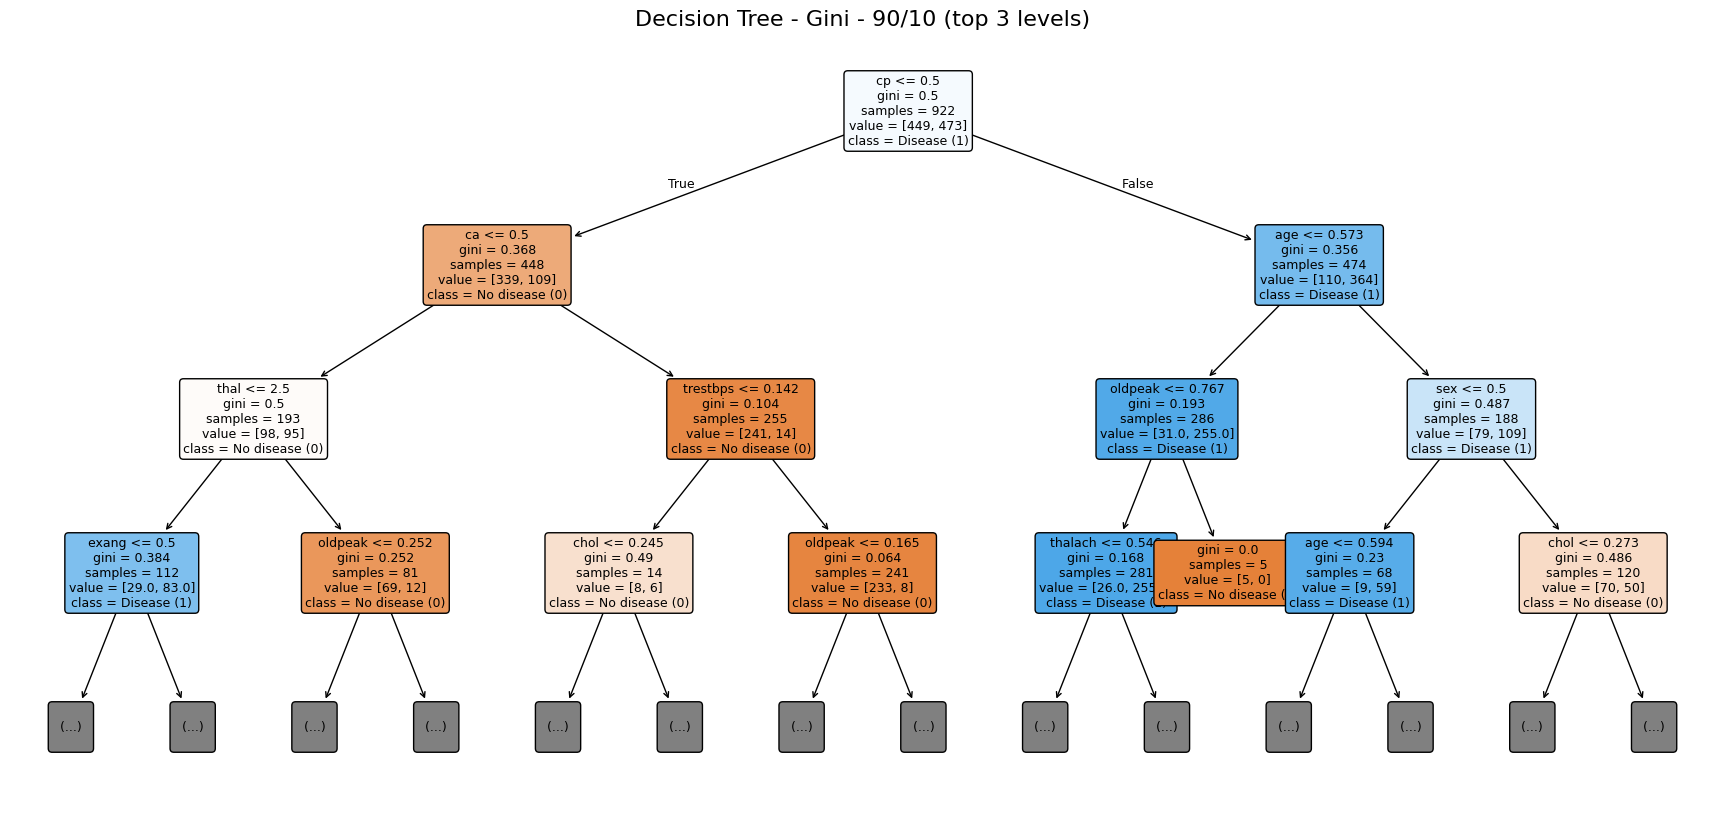

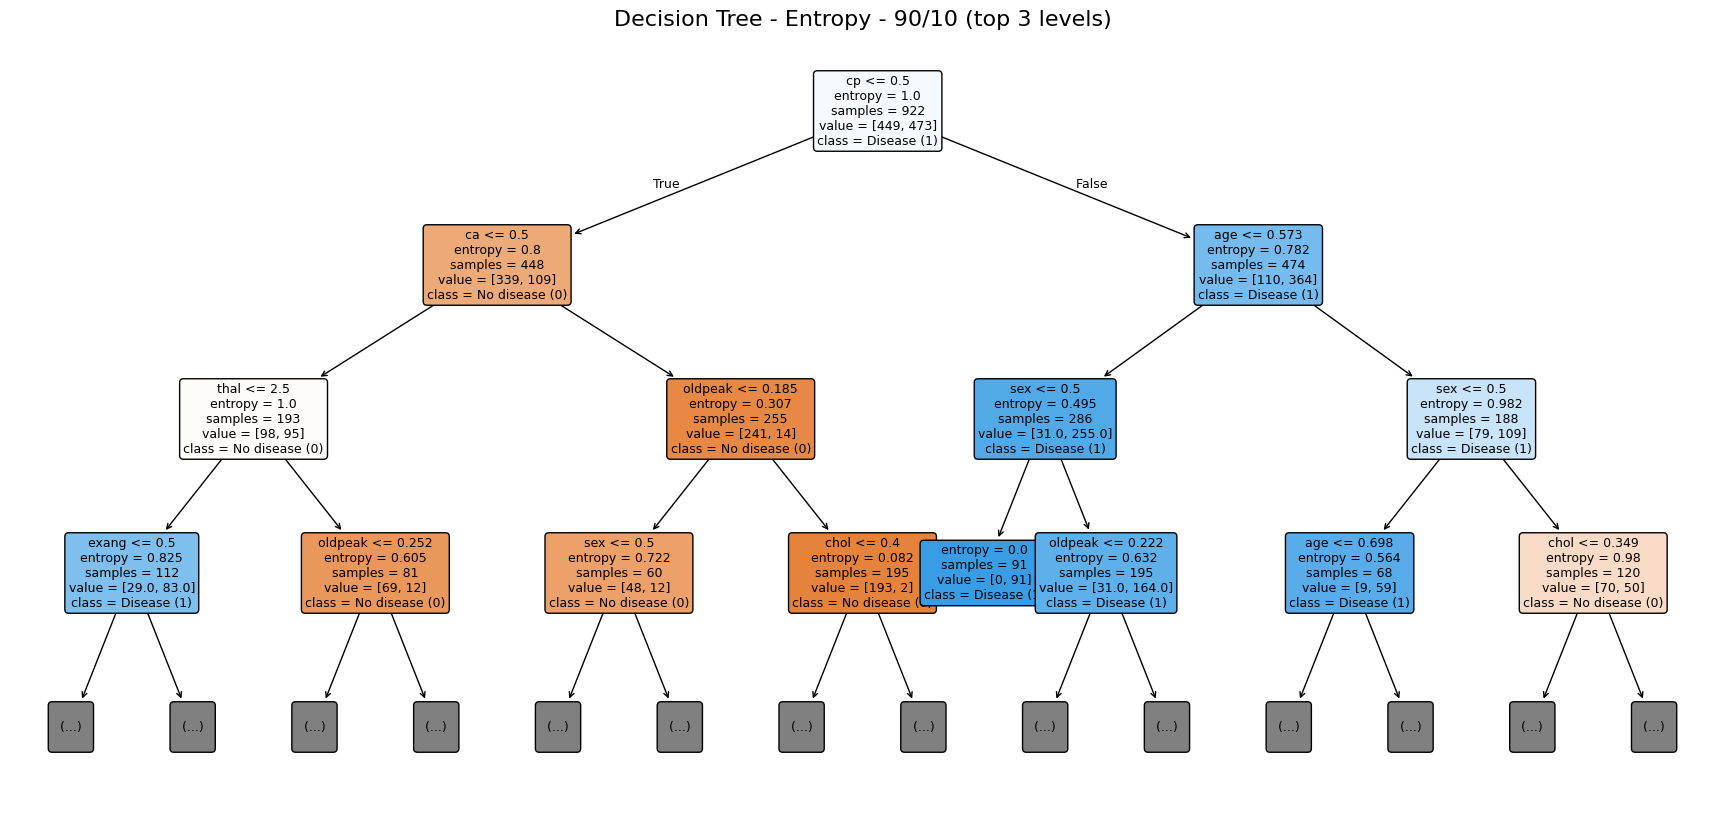

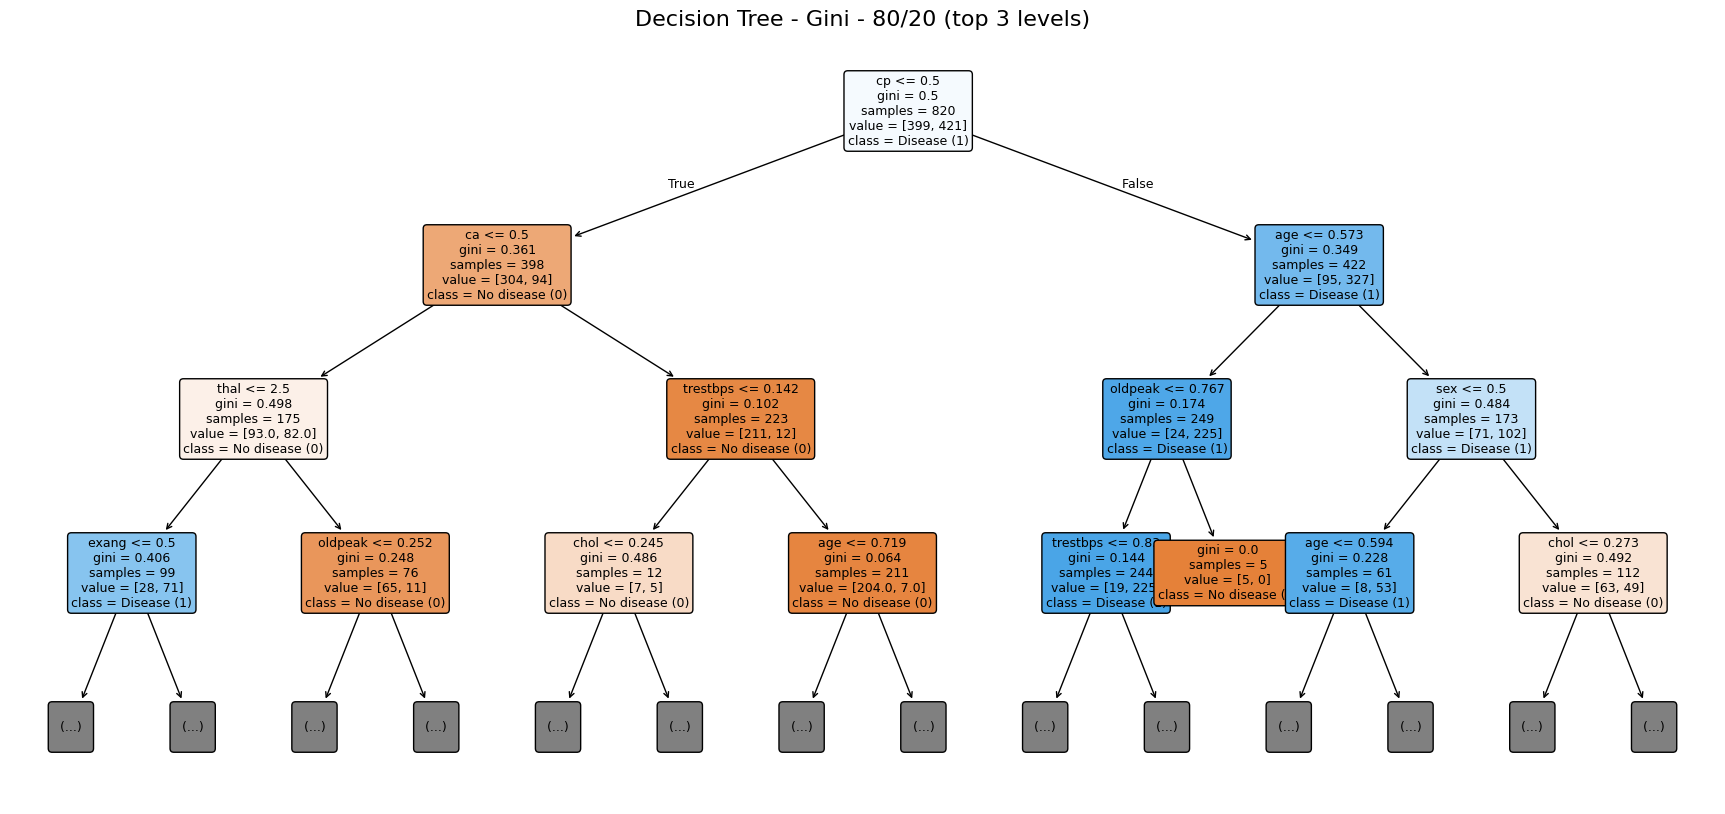

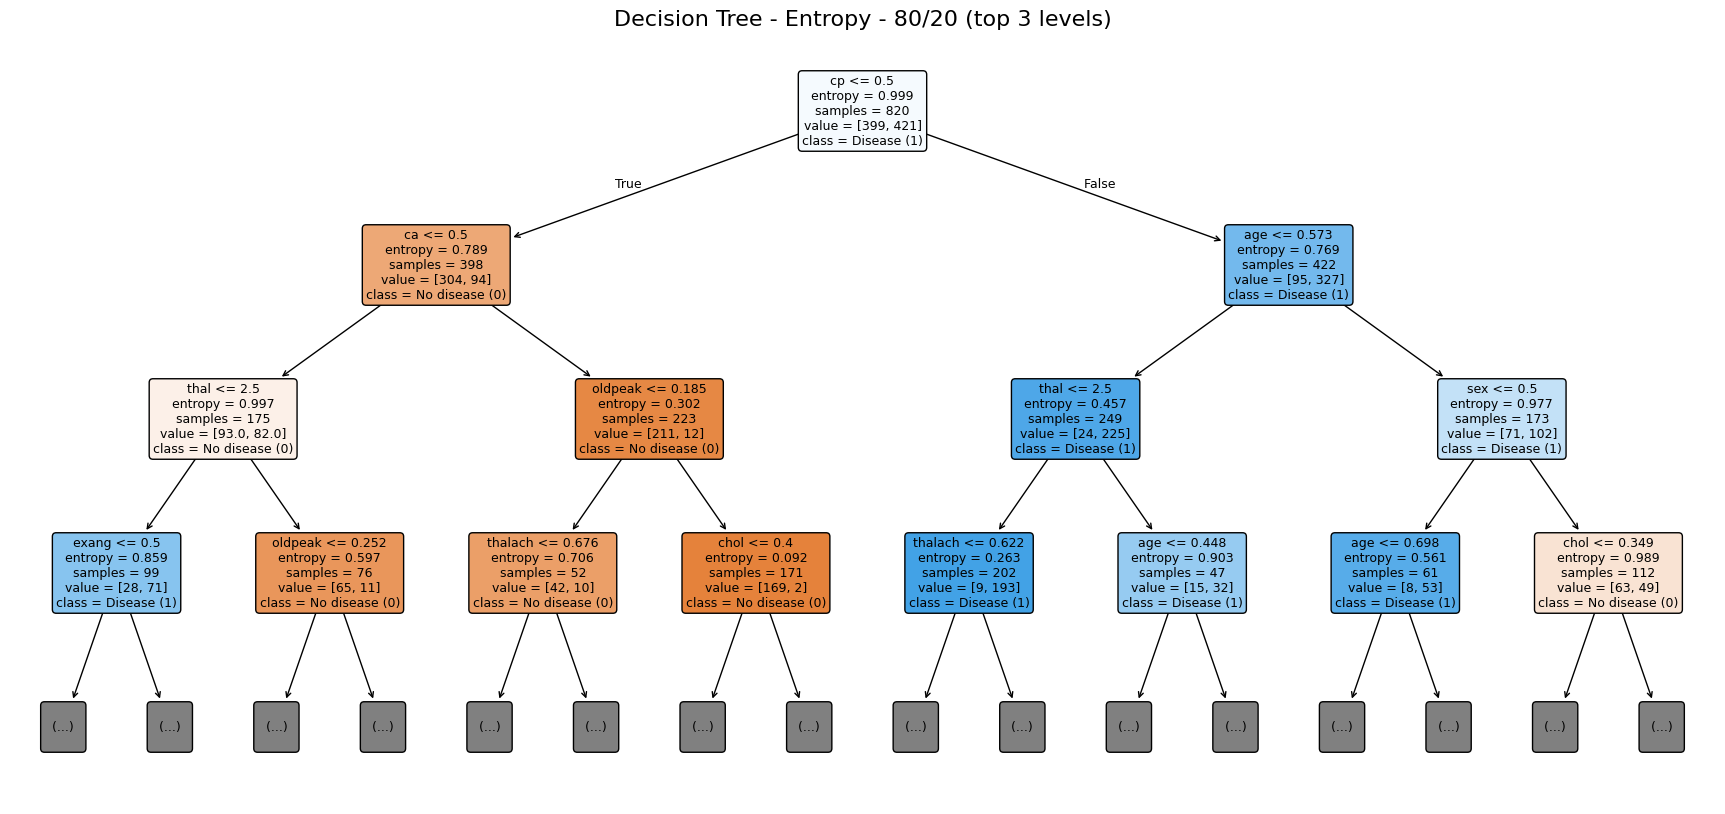

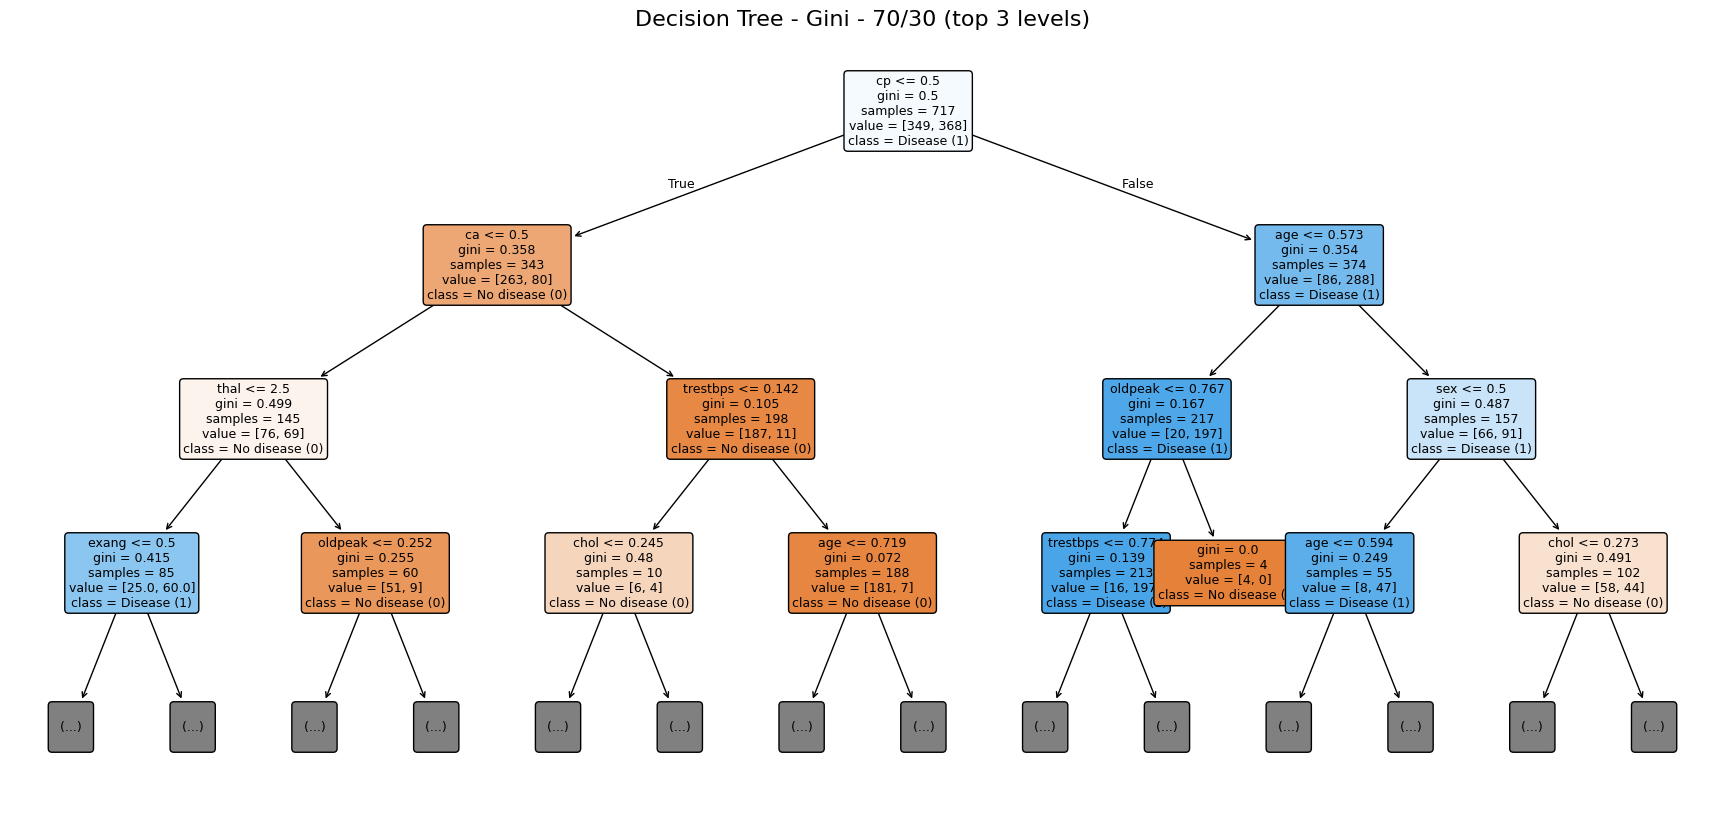

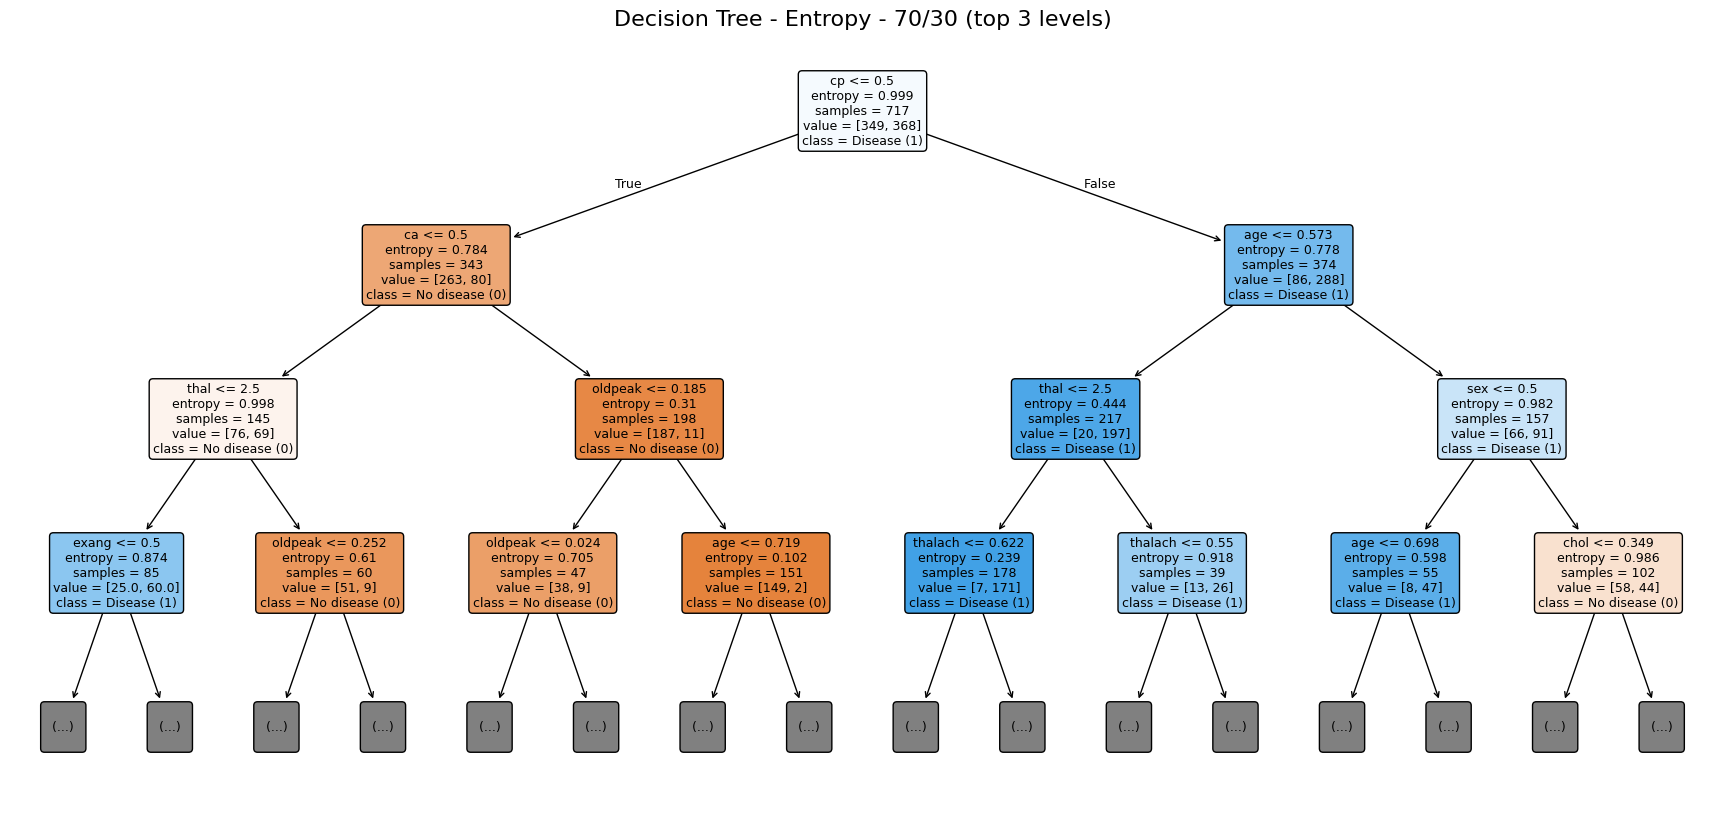

In [ ]:
feature_names = list(X.columns)
class_names = ['No disease (0)', 'Disease (1)']

for (c_name, p_name), model in models.items():
    plt.figure(figsize=(22, 10))
    plot_tree(model, feature_names=feature_names, class_names=class_names,
              filled=True, rounded=True, max_depth=3, fontsize=9)
    plt.title(f'Decision Tree - {c_name} - {p_name} (top 3 levels)', fontsize=16)
    plt.show()

###**6.1.2 Evaluating and Comparing the Decision Trees**

The 6 Decision Trees built in Section 6.1.1 are evaluated on their testing sets using Accuracy and the Confusion Matrix, together with Precision, Recall and F1-score. They are then compared across the two attribute selection measures (Gini vs Entropy) and the three partitions. Class 1 (heart disease) is the positive class.

| Metric | Formula | What it tells us |
|---|---|---|
| Accuracy | (TP + TN) / (TP + TN + FP + FN) | Share of all test patients classified correctly |
| Precision | TP / (TP + FP) | Of the patients predicted as sick, how many really are |
| Recall | TP / (TP + FN) | Of the patients who are really sick, how many the model found |
| F1-score | 2 × Precision × Recall / (Precision + Recall) | Balance between precision and recall |

- **TP:** a sick patient predicted as sick. **TN:** a healthy patient predicted as healthy.
- **FP:** a healthy patient predicted as sick (false alarm). **FN:** a sick patient predicted as healthy (missed patient).

In this problem, a false negative is the most dangerous error, because a patient with heart disease would not receive treatment.

#### 1. Accuracy of Each Model

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score

import seaborn as sns

rows = []
for (c_name, p_name), model in models.items():
    y_test = splits[p_name][3]
    y_pred = preds[(c_name, p_name)]
    rows.append({
        'Criterion': c_name,
        'Partition': p_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
    })

results = pd.DataFrame(rows)
results_display = results.copy()
for col in ['Accuracy', 'Precision', 'Recall', 'F1-score']:
    results_display[col] = (results_display[col] * 100).round(2).astype(str) + '%'
results_display

,Criterion,Partition,Accuracy,Precision,Recall,F1-score
0,Gini,90/10,100.0%,100.0%,100.0%,100.0%
1,Entropy,90/10,100.0%,100.0%,100.0%,100.0%
2,Gini,80/20,98.54%,100.0%,97.14%,98.55%
3,Entropy,80/20,100.0%,100.0%,100.0%,100.0%
4,Gini,70/30,98.05%,100.0%,96.2%,98.06%
5,Entropy,70/30,98.05%,98.1%,98.1%,98.1%


**Accuracy for each attribute selection measure:**

**Information Gain (Entropy)**

| | 90% training set, 10% testing set | 80% training set, 20% testing set | 70% training set, 30% testing set |
|---|---|---|---|
| Accuracy | 100.00% | 100.00% | 98.05% |

**Gini Index**

| | 90% training set, 10% testing set | 80% training set, 20% testing set | 70% training set, 30% testing set |
|---|---|---|---|
| Accuracy | 100.00% | 98.54% | 98.05% |

All six models achieve an accuracy above 98%. Accuracy is highest on the smallest testing set (90/10) and decreases slightly as the testing set grows, because a larger testing set contains more varied records and more chances for error.

Gini always has 100% precision (every patient it predicts as sick is really sick), but its recall drops to 97.14% (80/20) and 96.20% (70/30), meaning it misses some sick patients. Entropy keeps recall at 100% for 90/10 and 80/20 and 98.10% for 70/30.

#### 2. Confusion Matrix for Each Case
Rows = actual class, columns = predicted class (0 = no disease, 1 = disease).

In [ ]:
cm_rows = []
cms = {}
for (c_name, p_name), model in models.items():
    y_test = splits[p_name][3]
    cm = confusion_matrix(y_test, preds[(c_name, p_name)], labels=[0, 1])
    cms[(c_name, p_name)] = cm
    tn, fp, fn, tp = cm.ravel()
    cm_rows.append({'Criterion': c_name, 'Partition': p_name,
                    'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp})
pd.DataFrame(cm_rows)

,Criterion,Partition,TN,FP,FN,TP
0,Gini,90/10,50,0,0,53
1,Entropy,90/10,50,0,0,53
2,Gini,80/20,100,0,3,102
3,Entropy,80/20,100,0,0,105
4,Gini,70/30,150,0,6,152
5,Entropy,70/30,147,3,3,155


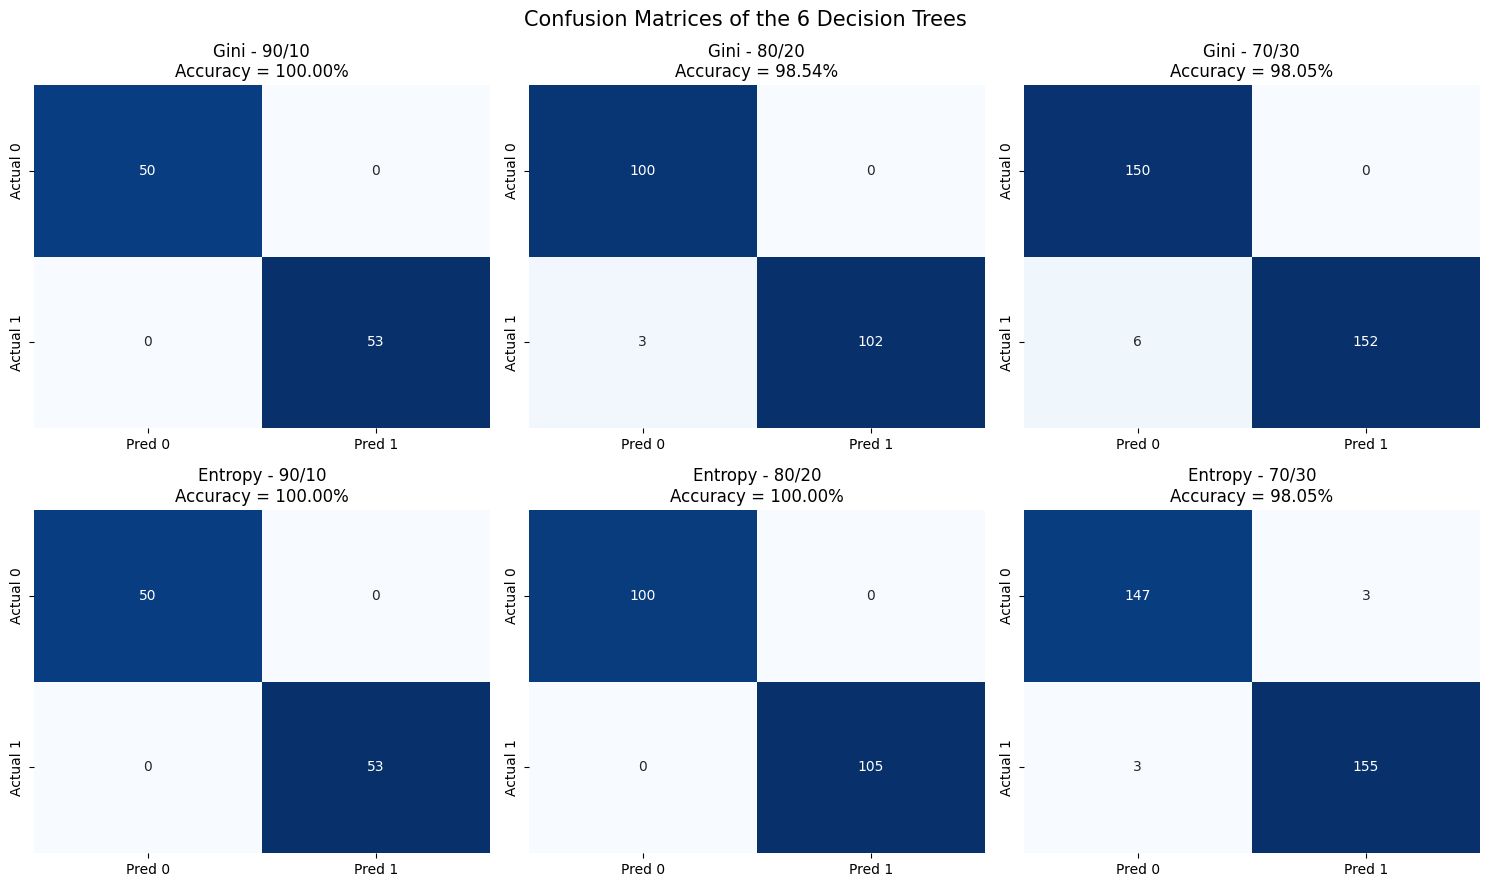

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for i, c_name in enumerate(criteria):
    for j, p_name in enumerate(partitions):
        ax = axes[i, j]
        sns.heatmap(cms[(c_name, p_name)], annot=True, fmt='d', cmap='Blues', cbar=False,
                    xticklabels=['Pred 0', 'Pred 1'], yticklabels=['Actual 0', 'Actual 1'], ax=ax)
        acc = results[(results.Criterion == c_name) & (results.Partition == p_name)]['Accuracy'].iloc[0]
        ax.set_title(f'{c_name} - {p_name}\nAccuracy = {acc*100:.2f}%')
plt.suptitle('Confusion Matrices of the 6 Decision Trees', fontsize=15)
plt.tight_layout()
plt.show()

**Interpretation of the confusion matrices:**

- **90/10 (103 test records):** both Gini and Entropy classify all records correctly (50 TN, 53 TP, no errors), so the two measures cannot be separated on this partition.
- **80/20 (205 test records):** Gini makes 3 errors, and all of them are false negatives (sick patients predicted as healthy). Entropy classifies all 205 records correctly. This is the only partition where the accuracy of the two measures differs.
- **70/30 (308 test records):** both models make 6 errors, so their accuracy is equal (98.05%), but the type of error differs. Gini has 6 false negatives and 0 false positives, while Entropy has 3 false positives and 3 false negatives. Entropy misses half as many sick patients, which is safer for medical diagnosis.

Across the three partitions, Gini misses 9 sick patients in total (0 + 3 + 6), while Entropy misses only 3 (0 + 0 + 3).

#### 3. Comparison Tables

In [ ]:
# Accuracy: rows = partition, columns = criterion
acc_table = results.pivot(index='Partition', columns='Criterion', values='Accuracy').loc[list(partitions)]
acc_table['Difference (Gini - Entropy)'] = acc_table['Gini'] - acc_table['Entropy']
(acc_table * 100).round(2)

Criterion,Entropy,Gini,Difference (Gini - Entropy)
Partition,,,
90/10,100.00,100.00,0.00
80/20,100.00,98.54,-1.46
70/30,98.05,98.05,0.00


In [ ]:
# Full metrics side by side
(results.set_index(['Partition', 'Criterion']) * 100).round(2)

Accuracy  Precision  Recall  F1-score
Partition Criterion                                       
90/10     Gini         100.00      100.0  100.00    100.00
          Entropy      100.00      100.0  100.00    100.00
80/20     Gini          98.54      100.0   97.14     98.55
          Entropy      100.00      100.0  100.00    100.00
70/30     Gini          98.05      100.0   96.20     98.06
          Entropy       98.05       98.1   98.10     98.10

The first table compares the accuracy of the two measures for each partition. The difference is 0 for 90/10 and 70/30, and −1.46 percentage points for 80/20, where Entropy is better. The second table shows that Entropy is equal to or better than Gini in accuracy, recall and F1-score on every partition, while Gini has slightly higher precision only at 70/30.

#### 4. Accuracy Chart

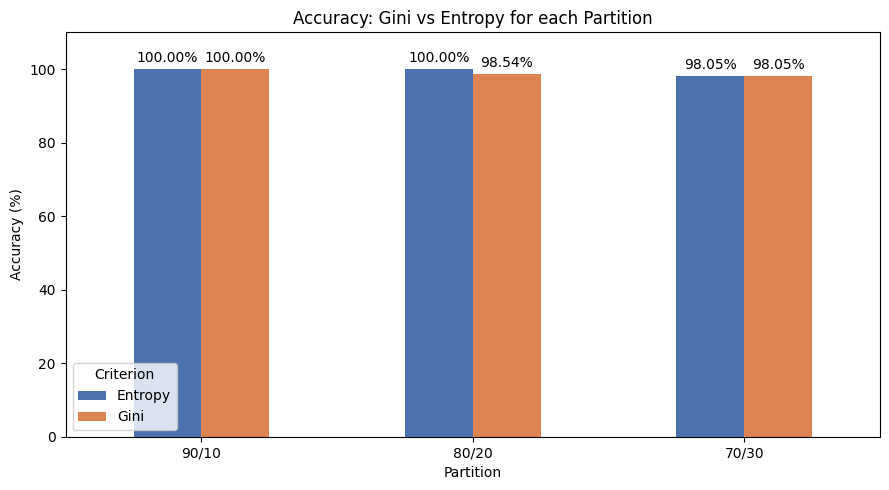

In [ ]:
acc_plot = results.pivot(index='Partition', columns='Criterion', values='Accuracy').loc[list(partitions)] * 100
ax = acc_plot.plot(kind='bar', figsize=(9, 5), color=['#4C72B0', '#DD8452'], rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3)
ax.set_ylabel('Accuracy (%)')
ax.set_ylim(0, 110)
ax.set_title('Accuracy: Gini vs Entropy for each Partition')
plt.legend(title='Criterion')
plt.tight_layout()
plt.show()

The bar chart shows the accuracy of Gini and Entropy side by side for each partition. The bars are equal for 90/10 and 70/30, and the only visible difference is the 80/20 partition, where Entropy (100%) is higher than Gini (98.54%). The chart also shows the slight decrease in accuracy as the testing set becomes larger.

#### 5. Gini vs Entropy

In [ ]:
# Average over the three partitions
avg = results.groupby('Criterion')[['Accuracy', 'Precision', 'Recall', 'F1-score']].mean() * 100
print('Average over the 3 partitions (%):')
display(avg.round(2))

# Winner per partition
print()
for p_name in partitions:
    g = acc_table.loc[p_name, 'Gini']
    e = acc_table.loc[p_name, 'Entropy']
    if g > e:   w = 'Gini'
    elif e > g: w = 'Entropy'
    else:       w = 'Tie'
    print(f'{p_name}: Gini = {g*100:.2f}%, Entropy = {e*100:.2f}%  ->  {w}')

Average over the 3 partitions (%):


,Accuracy,Precision,Recall,F1-score
Criterion,,,,
Entropy,99.35,99.37,99.37,99.37
Gini,98.86,100.00,97.78,98.87



90/10: Gini = 100.00%, Entropy = 100.00%  ->  Tie
80/20: Gini = 98.54%, Entropy = 100.00%  ->  Entropy
70/30: Gini = 98.05%, Entropy = 98.05%  ->  Tie


On average over the three partitions, Entropy achieves higher accuracy (99.35% vs 98.86%), recall (99.37% vs 97.78%) and F1-score (99.37% vs 98.87%). Gini has a higher average precision (100% vs 99.37%) because it never predicts a healthy patient as sick, but it pays for this with more missed sick patients.

#### 6. Best Model per Partition and Overall

In [ ]:
print('Best model per partition:')
for p_name in partitions:
    sub = results[results.Partition == p_name]
    top = sub['Accuracy'].max()
    winners = sub[sub['Accuracy'] == top]['Criterion'].tolist()
    label = ' & '.join(winners) + (' (tie)' if len(winners) > 1 else '')
    print(f'{p_name}: {label}  - accuracy = {top*100:.2f}%')

top = results['Accuracy'].max()
best_all = results[results['Accuracy'] == top]
print()
print('Overall best accuracy = {:.2f}% reached by:'.format(top*100))
display(best_all[['Criterion', 'Partition', 'Accuracy']].assign(Accuracy=lambda d: (d.Accuracy*100).round(2)))

Best model per partition:
90/10: Gini & Entropy (tie)  - accuracy = 100.00%
80/20: Entropy  - accuracy = 100.00%
70/30: Gini & Entropy (tie)  - accuracy = 98.05%

Overall best accuracy = 100.00% reached by:


,Criterion,Partition,Accuracy
0,Gini,90/10,100.0
1,Entropy,90/10,100.0
3,Entropy,80/20,100.0


**Best model for each partition:**

- **90/10:** Gini and Entropy are equally good (100%).
- **80/20:** Entropy is better (100% vs 98.54%).
- **70/30:** both have the same accuracy (98.05%), but Entropy is preferred because it has 3 false negatives instead of 6.

**Best model overall:** the Decision Tree using **Information Gain (Entropy)**. It is never worse than Gini on any partition, wins the 80/20 partition, reaches 100% accuracy on two partitions, and has the highest average accuracy (99.35%), recall and F1-score.

#### 7. Duplicate Check
The accuracies are very high, so we check whether duplicate rows could make the test set overlap with the training set.

In [ ]:
n_dup = df.duplicated().sum()
print(f'Duplicate rows in the dataset: {n_dup} out of {len(df)}')

Duplicate rows in the dataset: 723 out of 1025


The dataset contains **723 duplicate rows out of 1,025**, leaving only **302 unique records**. Because the data was split with the duplicates kept, many records in each testing set also appear in the training set, and a fully grown tree (depth 9–10, about 50 leaves) can recognize them instead of generalizing.

- The absolute accuracies are therefore **optimistic** and would likely be lower on new patients.
- The comparison between Gini and Entropy is still **fair**, because both measures were tested on exactly the same splits.
- This also explains why accuracy decreases as the testing set grows: a larger testing set includes more records that have no copy in the training set.


##6.2 Clustring: K-Mean
###**6.2.1 Summary Table of Results**

The K-Means clustering algorithm was evaluated using three different values of K: 2, 3, and 4. The Average Silhouette Width and Total Within-Cluster Sum of Squares (WCSS) were used as the main evaluation measures, as required by the project guidelines. The Calinski-Harabasz Index was also included as an additional metric to support the selection of the optimal number of clusters.

The results are summarized in the following table:

| Evaluation Metric | K = 2 | K = 3 | K = 4 |
|---|---:|---:|---:|
| Average Silhouette Width | 0.2455 | 0.2441 | 0.1934 |
| Total WCSS | 2969.31 | 2355.74 | 2124.55 |
| Calinski-Harabasz Index | 356.43 | 357.51 | 301.05 |

The results show that K = 2 achieved the highest Silhouette score, indicating relatively better-defined clusters according to this metric. K = 3 achieved the highest Calinski-Harabasz score. The WCSS decreased as the number of clusters increased, so the Elbow Method was used to examine the rate of decrease and identify a suitable number of clusters.



### **6.2.2 Interpretation of Results for Each K**

**K = 2**

When K = 2, the Silhouette score was **0.2455**, the highest among the three tested values. This indicates that K = 2 achieved the best clustering quality according to the Silhouette metric. However, its WCSS was **2969.31**, which was higher than the WCSS values obtained with K = 3 and K = 4. The Calinski-Harabasz Index was **356.43**, slightly lower than the score for K = 3.

**K = 3**

When K = 3, the Silhouette score was **0.2441**, which was very close to the score for K = 2. The WCSS decreased to **2355.74**, representing a substantial reduction compared with K = 2. In addition, K = 3 achieved the highest Calinski-Harabasz Index of **357.51**. The Elbow Method also favored K = 3 because the reduction in WCSS became smaller when increasing K from 3 to 4. These results suggest that K = 3 provides a reasonable balance between reducing within-cluster variation and avoiding unnecessary additional clusters.

**K = 4**

When K = 4, the WCSS reached its lowest value of **2124.55**. However, the Silhouette score decreased to **0.1934**, and the Calinski-Harabasz Index decreased to **301.05**. Although adding a fourth cluster reduced WCSS further, the improvement was smaller than the reduction observed when moving from K = 2 to K = 3. Therefore, K = 4 did not provide an overall improvement across the evaluation metrics.



### **6.2.3 Identifying the Best K Using Majority Rule**

To determine the most suitable number of clusters, the results of the three evaluation methods were compared using the majority rule.

| Evaluation Method | Preferred K | Reason |
|---|---:|---|
| Silhouette Coefficient | K = 2 | Achieved the highest Silhouette score of 0.2455. |
| Elbow Method (WCSS) | K = 3 | The decrease in WCSS became smaller after K = 3. |
| Calinski-Harabasz Index | K = 3 | Achieved the highest score of 357.51. |

Based on the majority rule, **K = 3 was selected as the preferred number of clusters**, since two out of the three evaluation methods favored this value. Although K = 2 achieved a slightly higher Silhouette score, K = 3 provided a reasonable balance between clustering quality and within-cluster variation.

However, the Silhouette scores were relatively low for all tested values, indicating that the clusters were not strongly separated. Therefore, the clustering results should be interpreted with caution.


### **6.2.4 Visualization of Clusters**

The clustering results were visualized using scatter plots to examine the distribution of records for K = 2, K = 3, and K = 4. Age (`age`) is represented on the x-axis, while Maximum Heart Rate (`thalach`) is represented on the y-axis. Different colors represent the clusters identified by the K-Means algorithm.

These visualizations help illustrate how the records are grouped for each value of K and allow us to compare the distribution and overlap of the identified clusters.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

df = pd.read_csv('Preprocessed_dataset.csv')
print(df.shape)


from sklearn.cluster import KMeans

X_cluster = df.drop(columns=['target', 'age_group'])

print("Clustering data shape:", X_cluster.shape)
X_cluster.head()

(1025, 15)
Clustering data shape: (1025, 13)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,0.479167,1,0,0.292453,0.196347,0,1,0.740458,0,0.351124,2,2,3
1,0.500000,1,0,0.433962,0.175799,1,0,0.641221,1,0.714756,0,0,3
2,0.854167,1,0,0.481132,0.109589,0,1,0.412214,1,0.648876,0,0,3
3,0.666667,1,0,0.509434,0.175799,0,1,0.687023,0,0.000000,2,1,3
4,0.687500,0,0,0.415094,0.383562,1,1,0.267176,0,0.539345,1,3,2


In [ ]:
k_values = [2, 3, 4]

kmeans_models = {}
cluster_labels = {}

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_cluster)

    kmeans_models[k] = kmeans
    cluster_labels[k] = labels

    print(f"K = {k}")
    print("Cluster counts:")
    print(pd.Series(labels).value_counts().sort_index())
    print()

K = 2
Cluster counts:
0    524
1    501
Name: count, dtype: int64

K = 3
Cluster counts:
0    353
1    468
2    204
Name: count, dtype: int64

K = 4
Cluster counts:
0    204
1    271
2    329
3    221
Name: count, dtype: int64



In [ ]:
from sklearn.metrics import silhouette_score

silhouette_scores = {}

for k in k_values:
    score = silhouette_score(X_cluster, cluster_labels[k])
    silhouette_scores[k] = score

    print(f"K = {k}, Average Silhouette Width = {score:.4f}")

K = 2, Average Silhouette Width = 0.2455
K = 3, Average Silhouette Width = 0.2441
K = 4, Average Silhouette Width = 0.1934


In [ ]:
wcss = {}

for k in k_values:
    wcss[k] = kmeans_models[k].inertia_

    print(f"K = {k}, Total WCSS = {wcss[k]:.2f}")

K = 2, Total WCSS = 2969.31
K = 3, Total WCSS = 2355.74
K = 4, Total WCSS = 2124.55


In [ ]:
from sklearn.metrics import calinski_harabasz_score

calinski_scores = {}

for k in k_values:
    score = calinski_harabasz_score(
        X_cluster,
        cluster_labels[k]
    )

    calinski_scores[k] = score

    print(f"K = {k}, Calinski-Harabasz Score = {score:.2f}")

K = 2, Calinski-Harabasz Score = 356.43
K = 3, Calinski-Harabasz Score = 357.51
K = 4, Calinski-Harabasz Score = 301.05


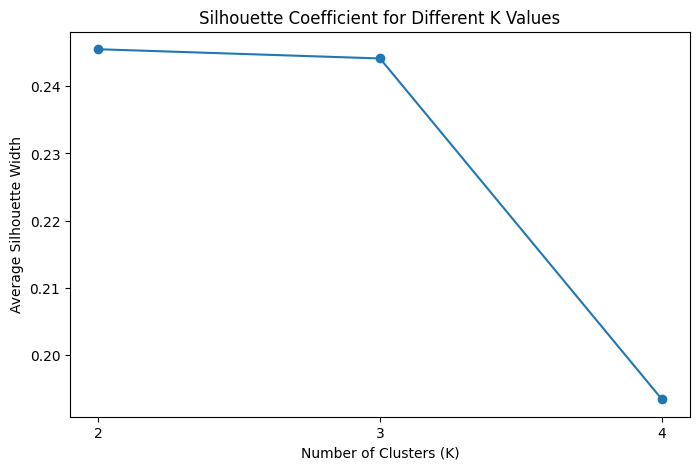

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    [silhouette_scores[k] for k in k_values],
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Average Silhouette Width')
plt.title('Silhouette Coefficient for Different K Values')
plt.xticks(k_values)

plt.show()

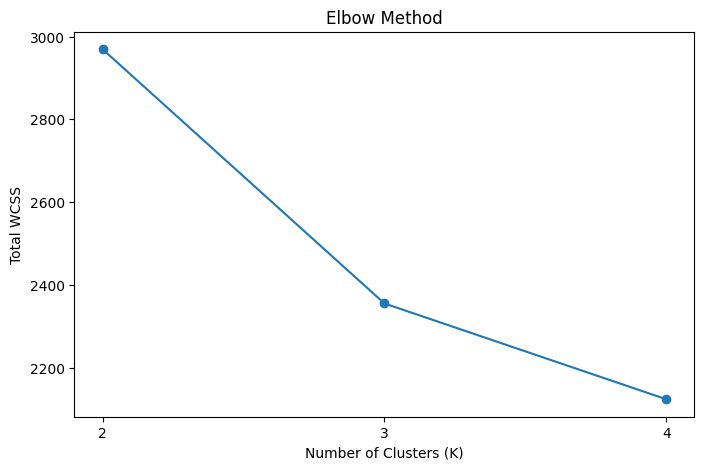

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    [wcss[k] for k in k_values],
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Total WCSS')
plt.title('Elbow Method')
plt.xticks(k_values)

plt.show()

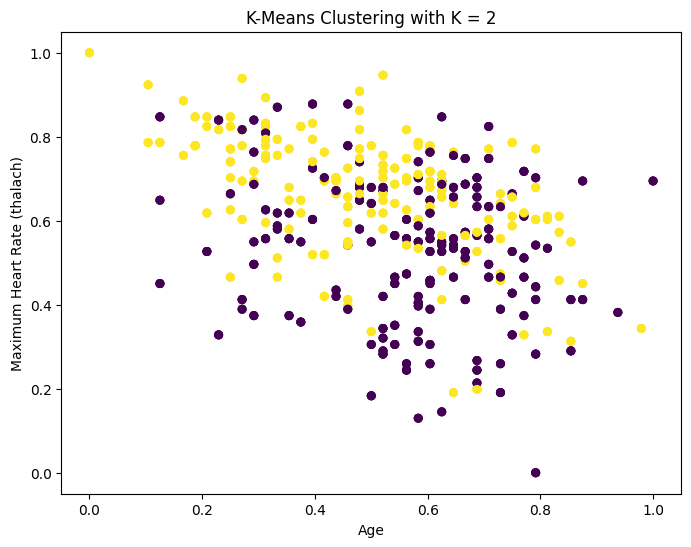

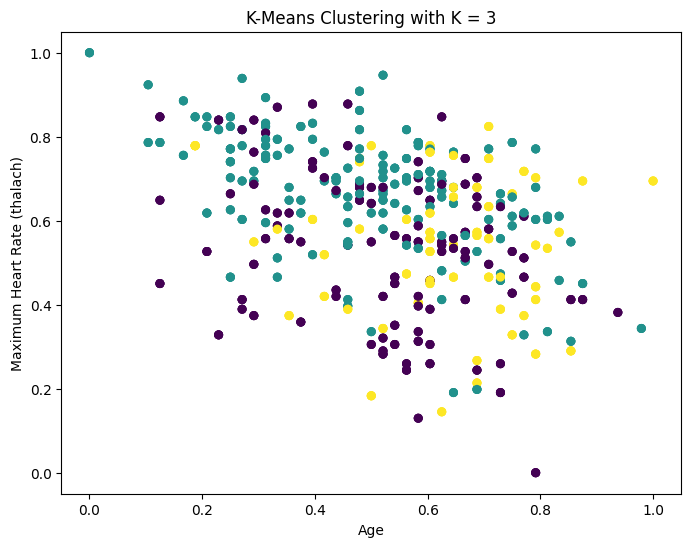

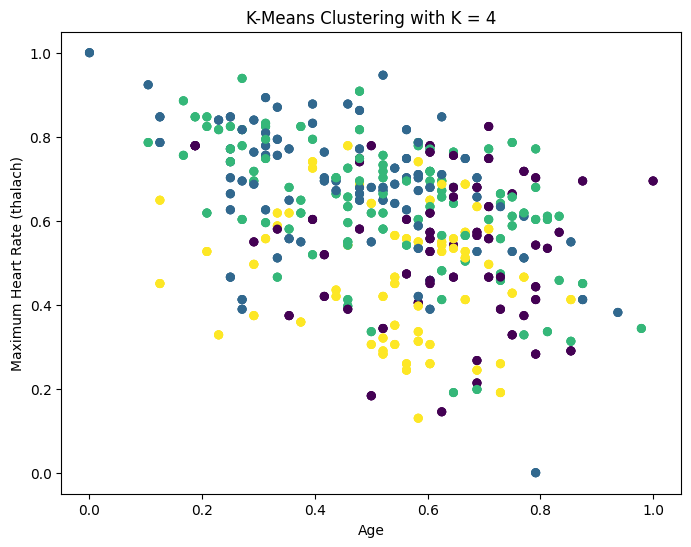

In [ ]:
# K-Means Clustering with K = 2
plt.figure(figsize=(8, 6))

plt.scatter(
    X_cluster['age'],
    X_cluster['thalach'],
    c=cluster_labels[2],
    cmap='viridis',
    s=30
)

plt.xlabel('Age')
plt.ylabel('Maximum Heart Rate (thalach)')
plt.title('K-Means Clustering with K = 2')
plt.show()


# K-Means Clustering with K = 3
plt.figure(figsize=(8, 6))

plt.scatter(
    X_cluster['age'],
    X_cluster['thalach'],
    c=cluster_labels[3],
    cmap='viridis',
    s=30
)

plt.xlabel('Age')
plt.ylabel('Maximum Heart Rate (thalach)')
plt.title('K-Means Clustering with K = 3')
plt.show()


# K-Means Clustering with K = 4
plt.figure(figsize=(8, 6))

plt.scatter(
    X_cluster['age'],
    X_cluster['thalach'],
    c=cluster_labels[4],
    cmap='viridis',
    s=30
)

plt.xlabel('Age')
plt.ylabel('Maximum Heart Rate (thalach)')
plt.title('K-Means Clustering with K = 4')
plt.show()

##7. Findings and Discussion

##8. References